In [1]:
import matplotlib.pyplot as plt
import pickle as pkl

In [2]:
variables={
    2:['tos','tas','psl','pr'],
    3:['tos','tas','psl','pr','mrso','siconc','monmaxtasmax'] 
}

### Load the metrics from the folder 

In [3]:
def load_from_files(variable,tier):
    comparison_folder='evaluation_metrics'
    methods=['DMDc','DMDc-opt','DMDc-p']

    with open(f'{comparison_folder}/original_data/{variable}_tier{tier}.pkl3', 'rb') as f: 
        ids, single_items_original_data=pkl.load(f)

    single_items_estimated={}
    for method in methods:
        with open(f'{comparison_folder}/{method}/{variable}_tier{tier}.pkl3', 'rb') as f: 
            ids, single_items_estimated[method]=pkl.load(f)

    id=ids[0]
    return methods, id, single_items_original_data, single_items_estimated

### Plot the time series (various single metrics define them, check the 'metric' variable). 

colors = methods' estimates of the ground truth, 

gray = original data 

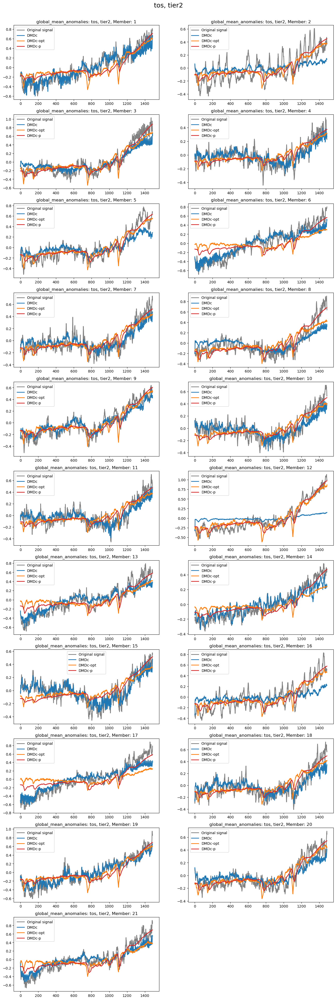

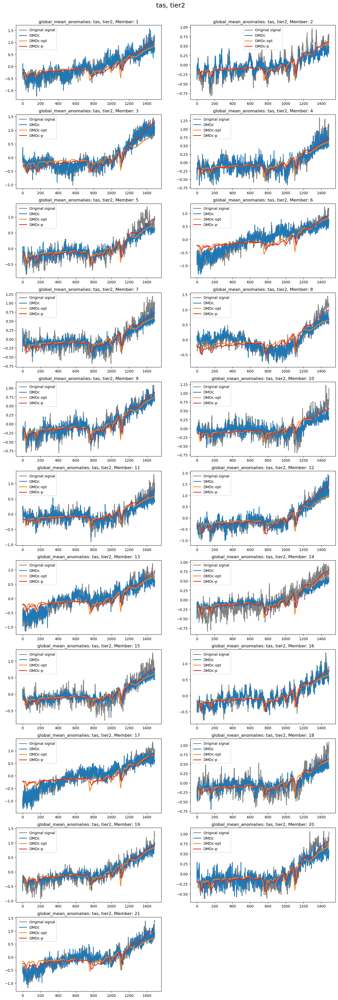

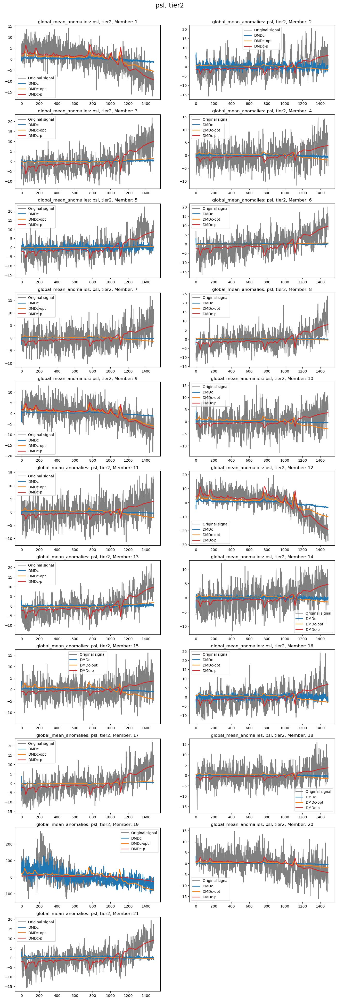

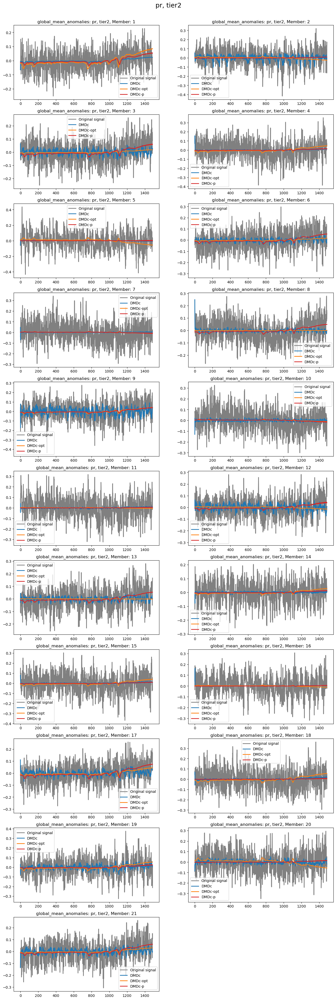

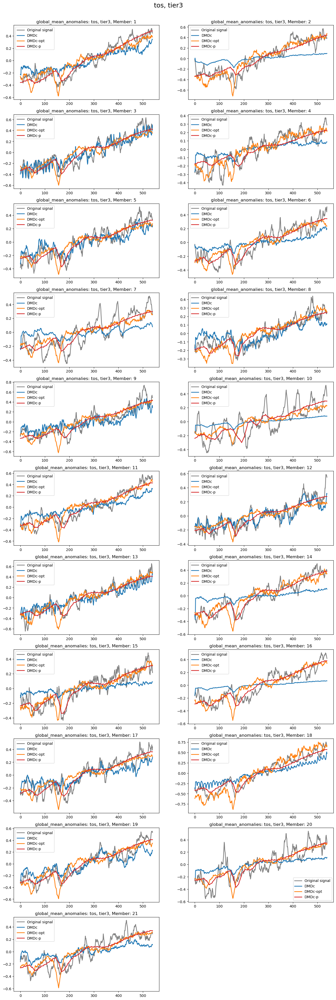

...

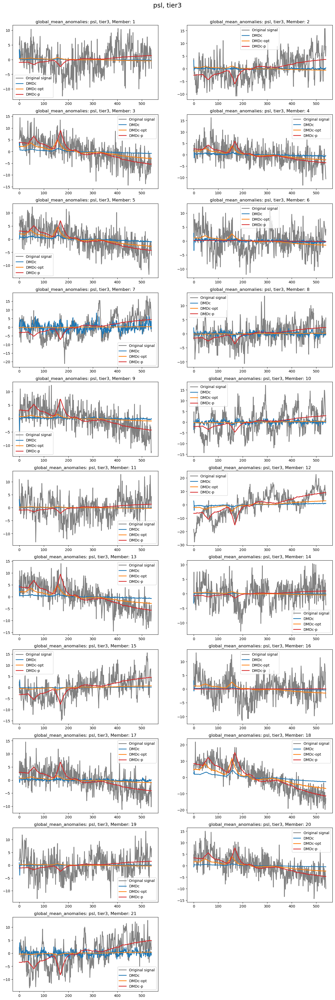

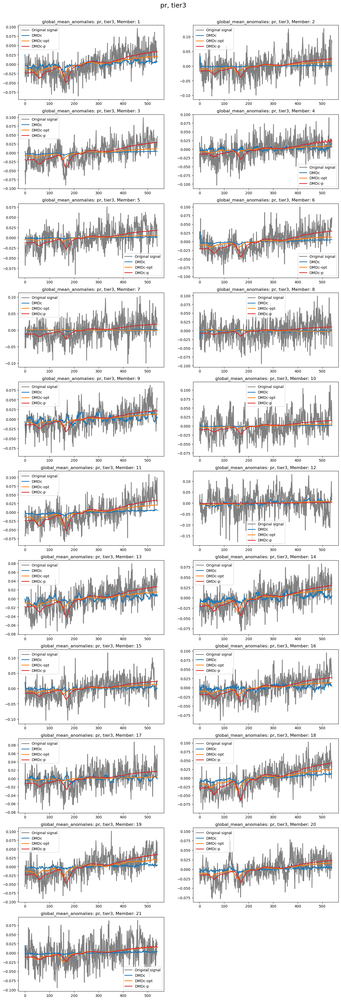

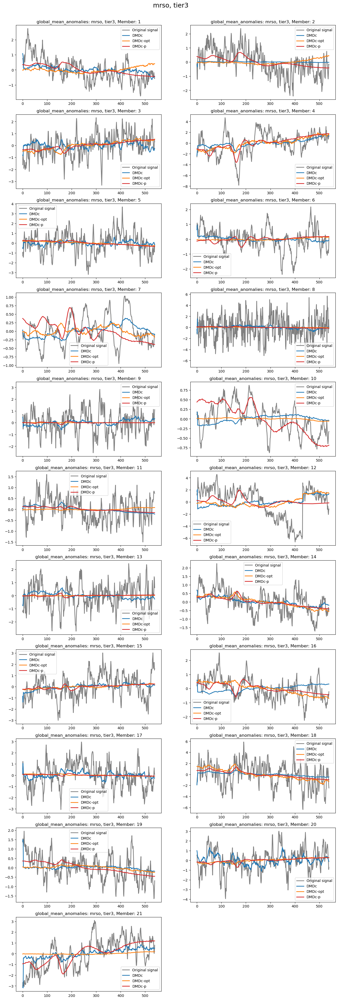

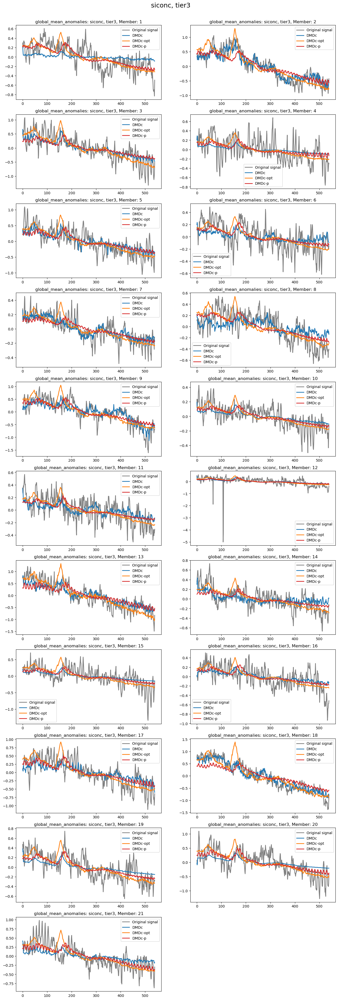

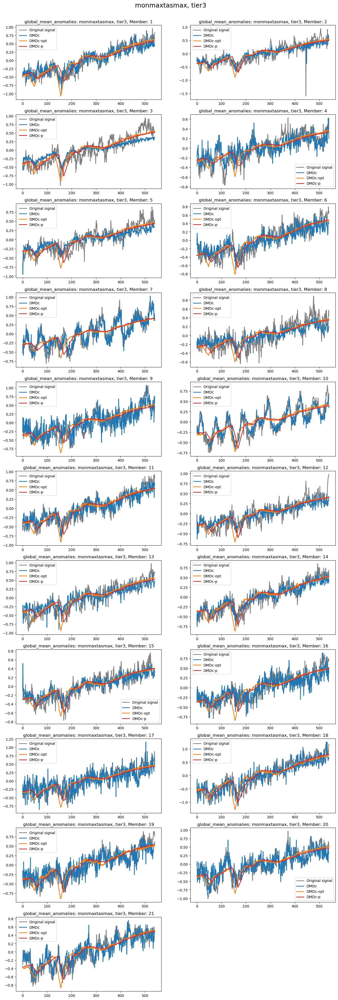

In [4]:
colors=['tab:blue','tab:orange','tab:red']
for tier in [2,3]:
    for variable in variables[tier]:
        methods, id, single_items_original_data, single_items_estimated=load_from_files(variable,tier)
        #print(id, single_items_original_data)
        for metric in ['global_mean_anomalies']:#,'global_mean']:
            fig=plt.figure(figsize=(8*2,4*11))
            fig.suptitle(f'{variable}, tier{tier}',fontsize=18)
            fig.subplots_adjust(top=0.96)
            c=1
            x=single_items_original_data[id][metric]
            y={method:single_items_estimated[method][id][metric] for method in methods}
            ns,nt=x.shape
            for i in range(ns):    
                ax=fig.add_subplot(11,2,c)
                ax.plot(x[i,:],'-',color='gray',label='Original signal', linewidth=2)
                for method, color in zip(methods, colors):
                    ax.plot(y[method][i,:], '-',label=f'{method}', linewidth=2, color=color)
                ax.legend()
                ax.set_title(f'{metric}: {variable}, tier{tier}, Member: {c}')
                c+=1
            plt.show()